# モデル2の解析: 自分だけ学習するとき、最適な戦略はどれか

モデル2では、学習者1人(ノード0)だけが配分を変え、他の人の配分はランダムなまま固定されます。
このノートでは次の順に解析します。

1. **平均場近似**: 張る力の関数形から、最適配分を解析的に予測する
2. **最適反応の地形**: 学習者の配分を格子で総当たりし、本当の最適点を測る
3. **時間スケール**: 短期と長期で最適配分が変わるかを見る
4. **学習の診断**: 学習が最適点に届くか、届かないならなぜかを調べる

計算は `python3 src/model2_compute.py all [シード数]` で行い、結果は `results/model2/` に保存されます。
このノートは保存済みの結果を読み込むだけです。シード数が1だと地形に雑音が残るので、結論には複数シードの結果を使ってください。

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
sys.path.insert(0, os.path.abspath('../src'))
from sim import DEFAULT, power
from model2_tools import simplex_grid, mean_field_power
from model2_compute import LEARN_CONFIGS, STARTS

R2 = '../results/model2'
G = np.load(f'{R2}/grid.npz'); L = np.load(f'{R2}/learn.npz')
grid = G['grid']
print('grid points:', len(grid), ' seeds per point:', G['steady'].shape[1])

def tern(x):
    x = np.atleast_2d(x); return x[:, 1] + 0.5 * x[:, 2], np.sqrt(3) / 2 * x[:, 2]

# 頂点ラベルの色と大きさ (results/model2_trajectories.png と同じ仕様)
LABEL_COLORS = {'acquaint': 'tab:blue', 'research': 'tab:orange', 'outreach': 'tab:green'}
LABEL_SIZE = 16

def tri_axes(ax, title):
    """三角図の枠と頂点ラベル。ラベルは各頂点の真下・真上に中央揃えで置く(カラーバーと重ならない)"""
    ax.plot([0, 1, 0.5, 0], [0, 0, np.sqrt(3)/2, 0], 'k-', lw=0.8)
    ax.text(0, -0.04, 'r1 acquaint.', ha='center', va='top', fontsize=LABEL_SIZE, color=LABEL_COLORS['acquaint'])
    ax.text(1, -0.04, 'r2 research', ha='center', va='top', fontsize=LABEL_SIZE, color=LABEL_COLORS['research'])
    ax.text(0.5, np.sqrt(3)/2 + 0.03, 'r3 outreach', ha='center', va='bottom', fontsize=LABEL_SIZE, color=LABEL_COLORS['outreach'])
    ax.set_xlim(-0.25, 1.25); ax.set_ylim(-0.2, np.sqrt(3)/2 + 0.2)
    if title: ax.set_title(title, fontsize=12, pad=8)
    ax.set_aspect('equal'); ax.axis('off')

def tri_map(ax, pts, val, title, cmap='viridis', mark_max=True):
    u, w = tern(pts)
    cs = ax.tricontourf(mtri.Triangulation(u, w), val, levels=14, cmap=cmap)
    plt.colorbar(cs, ax=ax, shrink=0.7); tri_axes(ax, title)
    if mark_max:
        i = np.argmax(val); ax.plot(*tern(pts[i]), 'r*', ms=14, mec='w')
    ax.plot(*tern([1/3, 1/3, 1/3]), 'wo', ms=6, mec='k')
    return pts[np.argmax(val)]

grid points: 231  seeds per point: 12


## 1. 平均場近似

定常状態ではストックが $S_k = R x_k / \delta$ に落ち着きます。そこで、自分が1ステップに張るリンク数の期待値

$$F(x) = f_1(R x_1/\delta) + f_2(R x_2/\delta) + f_3(R x_3/\delta)$$

を最大にする配分を、最適配分の予測とします。定常での次数はおよそ「自分が張る分 + 他人から張られる分」を $\mu$ で割ったものです。他人から張られる分が自分の配分にあまり依存しないなら、$F$ の最大点が最適になります。

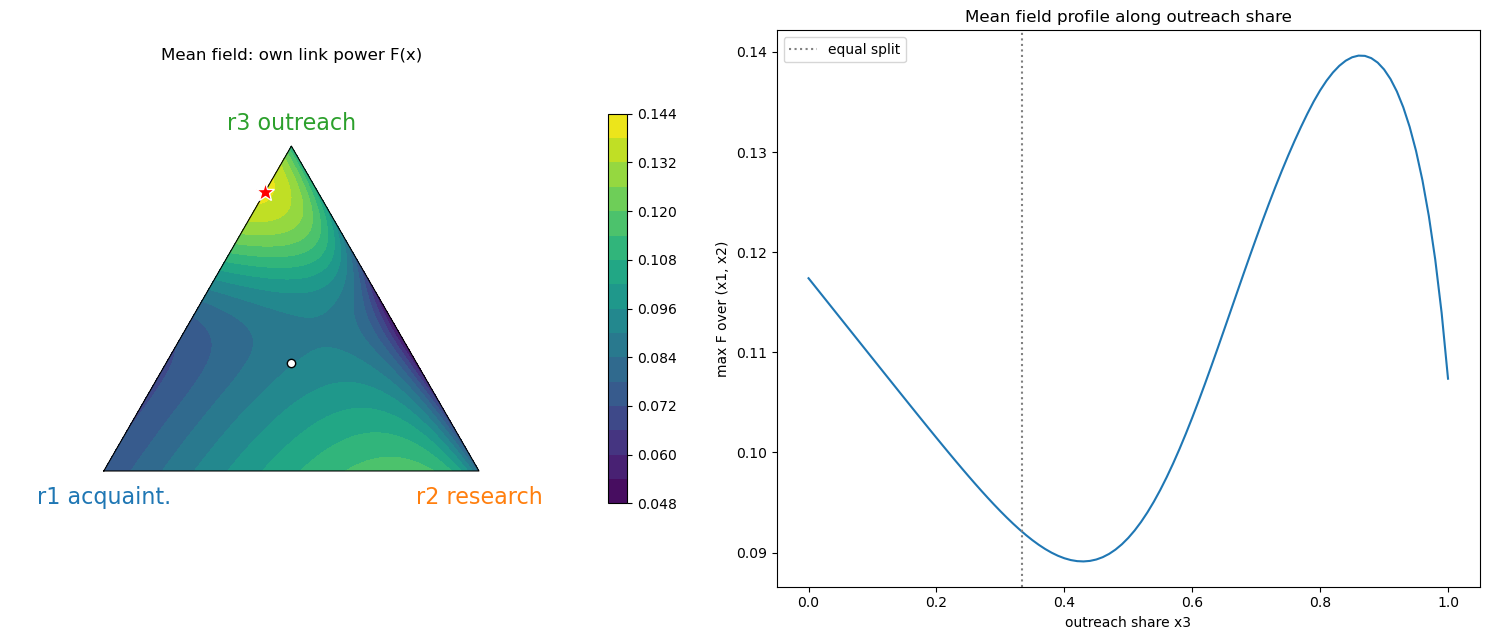

mean-field global optimum: [0.14 0.   0.86] F = 0.1396
mean-field local optimum (low outreach): [0.22 0.78 0.  ] F = 0.1174
equal split F = 0.0896


In [2]:
fine = simplex_grid(0.01)
F = mean_field_power(fine)
fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
opt_mf = tri_map(axs[0], fine, F, 'Mean field: own link power F(x)')

# アウトリーチの割合ごとに、残りを最適に分けたときの F
x3s = np.round(np.arange(0, 1.001, 0.01), 2)
prof = [F[np.isclose(fine[:, 2], v)].max() for v in x3s]
axs[1].plot(x3s, prof); axs[1].axvline(1/3, color='gray', ls=':', label='equal split')
axs[1].set_xlabel('outreach share x3'); axs[1].set_ylabel('max F over (x1, x2)')
axs[1].set_title('Mean field profile along outreach share'); axs[1].legend()
plt.tight_layout(); plt.show()

print('mean-field global optimum:', opt_mf, 'F =', F.max().round(4))
loc = fine[fine[:, 2] < 0.3][F[fine[:, 2] < 0.3].argmax()]
print('mean-field local optimum (low outreach):', loc, 'F =', mean_field_power(loc)[0].round(4))
print('equal split F =', mean_field_power([1/3, 1/3, 1/3])[0].round(4))

**読み方**: 地形には山が2つあります。アウトリーチに大きく振る山(大域最適)と、研究に大きく振る山(局所最適)です。
均等配分(白丸)は2つの山のあいだの谷にあります。アウトリーチの張る力は閾値型なので、割合が半分を超えるまでほとんど効きません。

## 2. 最適反応の地形(シミュレーション)

学習者の配分を0.05刻みの格子に固定し、定常状態(300〜600ステップ)の平均次数を測りました。他の人の配分とラベルは、シードが同じなら全格子点で共通です。

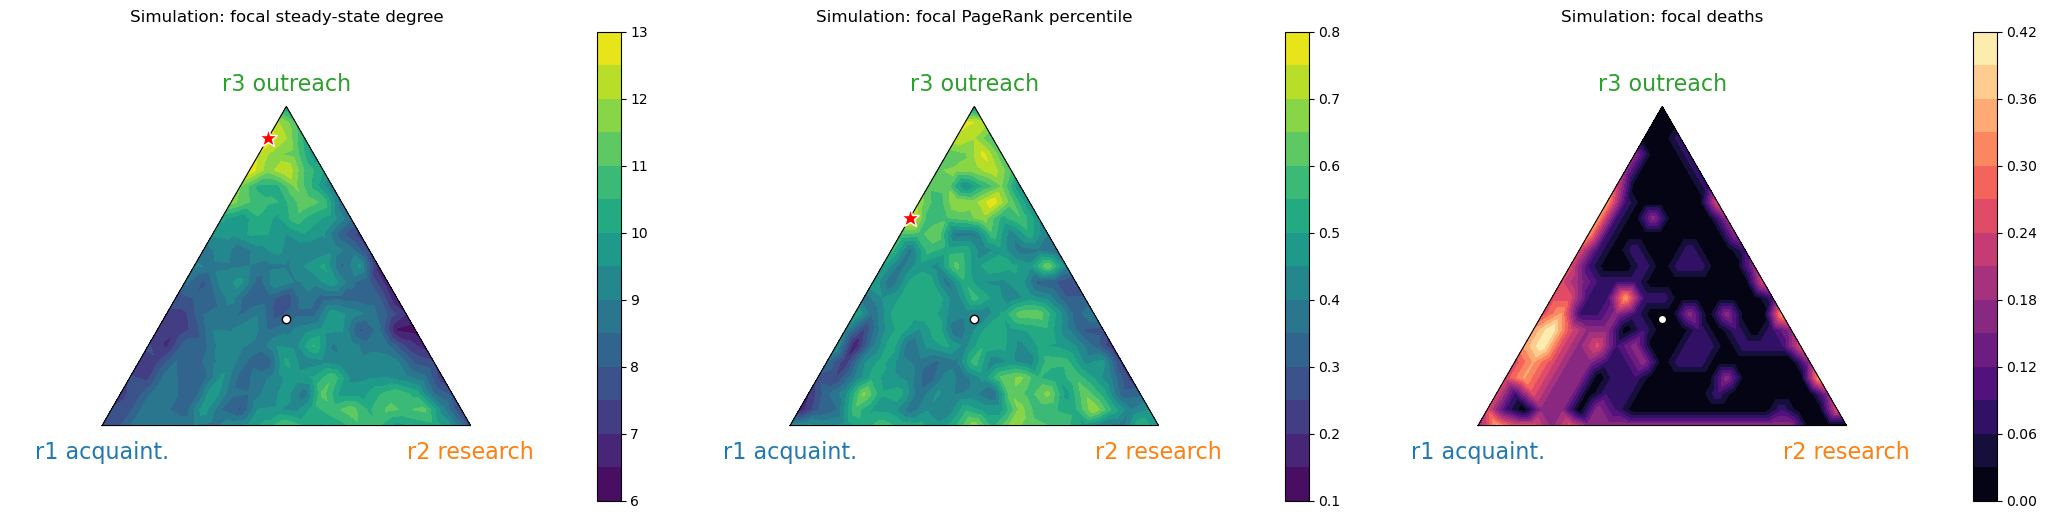

best by degree  : [0.1 0.  0.9] degree = 12.93
best by PageRank: [0.35 0.   0.65]
near equal split: [0.3  0.35 0.35] degree = 8.32
population mean degree: 9.39


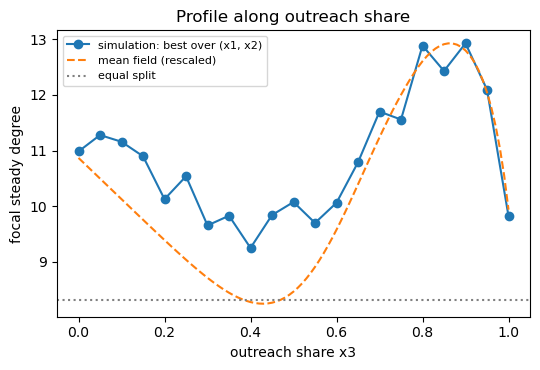

x3=0.00: best degree 10.99 at [0.5 0.5 0. ]
x3=0.05: best degree 11.28 at [0.3  0.65 0.05]
x3=0.10: best degree 11.16 at [0.35 0.55 0.1 ]
x3=0.15: best degree 10.90 at [0.3  0.55 0.15]
x3=0.20: best degree 10.13 at [0.4 0.4 0.2]
x3=0.25: best degree 10.54 at [0.3  0.45 0.25]
x3=0.30: best degree  9.66 at [0.25 0.45 0.3 ]
x3=0.35: best degree  9.83 at [0.2  0.45 0.35]
x3=0.40: best degree  9.25 at [0.45 0.15 0.4 ]
x3=0.45: best degree  9.84 at [0.15 0.4  0.45]
x3=0.50: best degree 10.08 at [0.15 0.35 0.5 ]
x3=0.55: best degree  9.70 at [0.25 0.2  0.55]
x3=0.60: best degree 10.06 at [0.3 0.1 0.6]
x3=0.65: best degree 10.79 at [0.15 0.2  0.65]
x3=0.70: best degree 11.70 at [0.3 0.  0.7]
x3=0.75: best degree 11.56 at [0.1  0.15 0.75]
x3=0.80: best degree 12.89 at [0.2 0.  0.8]
x3=0.85: best degree 12.43 at [0.15 0.   0.85]
x3=0.90: best degree 12.93 at [0.1 0.  0.9]
x3=0.95: best degree 12.10 at [0.05 0.   0.95]
x3=1.00: best degree  9.83 at [0. 0. 1.]
typical standard error per grid point

In [3]:
steady = G['steady'].mean(1)
pr = G['pr_pct'].mean(1)
deaths = G['deaths'].mean(1)
fig, axs = plt.subplots(1, 3, figsize=(21, 7))
opt_sim = tri_map(axs[0], grid, steady, 'Simulation: focal steady-state degree')
opt_pr = tri_map(axs[1], grid, pr, 'Simulation: focal PageRank percentile')
tri_map(axs[2], grid, deaths, 'Simulation: focal deaths', cmap='magma', mark_max=False)
plt.tight_layout(); plt.show()

ctr = np.argmin(np.abs(grid - 1/3).sum(1))
print('best by degree  :', opt_sim, 'degree =', steady.max().round(2))
print('best by PageRank:', opt_pr)
print('near equal split:', grid[ctr], 'degree =', steady[ctr].round(2))
print('population mean degree:', G['pop_deg'].mean().round(2))

# 研究寄りの山は本当にあるか: アウトリーチ割合ごとの最良の次数
se = G['steady'].std(1) / np.sqrt(G['steady'].shape[1])
x3v = np.unique(grid[:, 2].round(2))
best = np.array([steady[np.isclose(grid[:, 2], v)].max() for v in x3v])
arg  = [grid[np.isclose(grid[:, 2], v)][steady[np.isclose(grid[:, 2], v)].argmax()] for v in x3v]
plt.figure(figsize=(5.5, 3.8))
plt.plot(x3v, best, 'o-', label='simulation: best over (x1, x2)')
plt.plot(x3s, np.array(prof) / max(prof) * best.max(), '--', label='mean field (rescaled)')
plt.axhline(steady[ctr], color='gray', ls=':', label='equal split')
plt.xlabel('outreach share x3'); plt.ylabel('focal steady degree'); plt.legend(fontsize=8)
plt.title('Profile along outreach share'); plt.tight_layout(); plt.show()
for v, b, a in zip(x3v, best, arg):
    print(f'x3={v:.2f}: best degree {b:5.2f} at {a}')
print('typical standard error per grid point:', np.median(se).round(2))

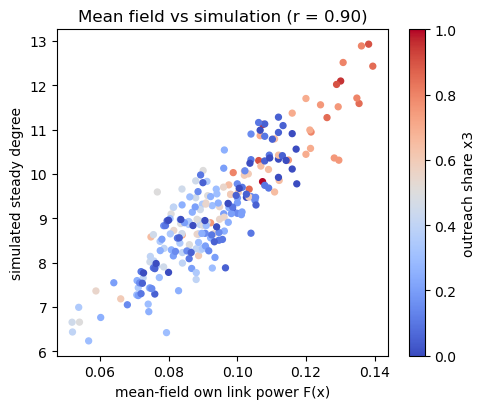

In [4]:
# 平均場とシミュレーションの比較: 同じ格子点での散布図
Fg = mean_field_power(grid)
plt.figure(figsize=(5, 4.2))
sc = plt.scatter(Fg, steady, c=grid[:, 2], cmap='coolwarm', s=18)
plt.colorbar(sc, label='outreach share x3')
plt.xlabel('mean-field own link power F(x)'); plt.ylabel('simulated steady degree')
r = np.corrcoef(Fg, steady)[0, 1]
plt.title(f'Mean field vs simulation (r = {r:.2f})'); plt.tight_layout(); plt.show()

## 3. 時間スケール: 短期と長期で最適は変わるか

開始から $H$ ステップまでの平均次数で評価すると、最適配分がどう動くかを見ます。アウトリーチはストックが貯まるまで効かないので、短期では不利になるはずです。

H =   50: best allocation [0.5  0.35 0.15]
H =  100: best allocation [0.05 0.05 0.9 ]
H =  200: best allocation [0.05 0.05 0.9 ]
H =  300: best allocation [0.05 0.05 0.9 ]
H =  600: best allocation [0.05 0.05 0.9 ]


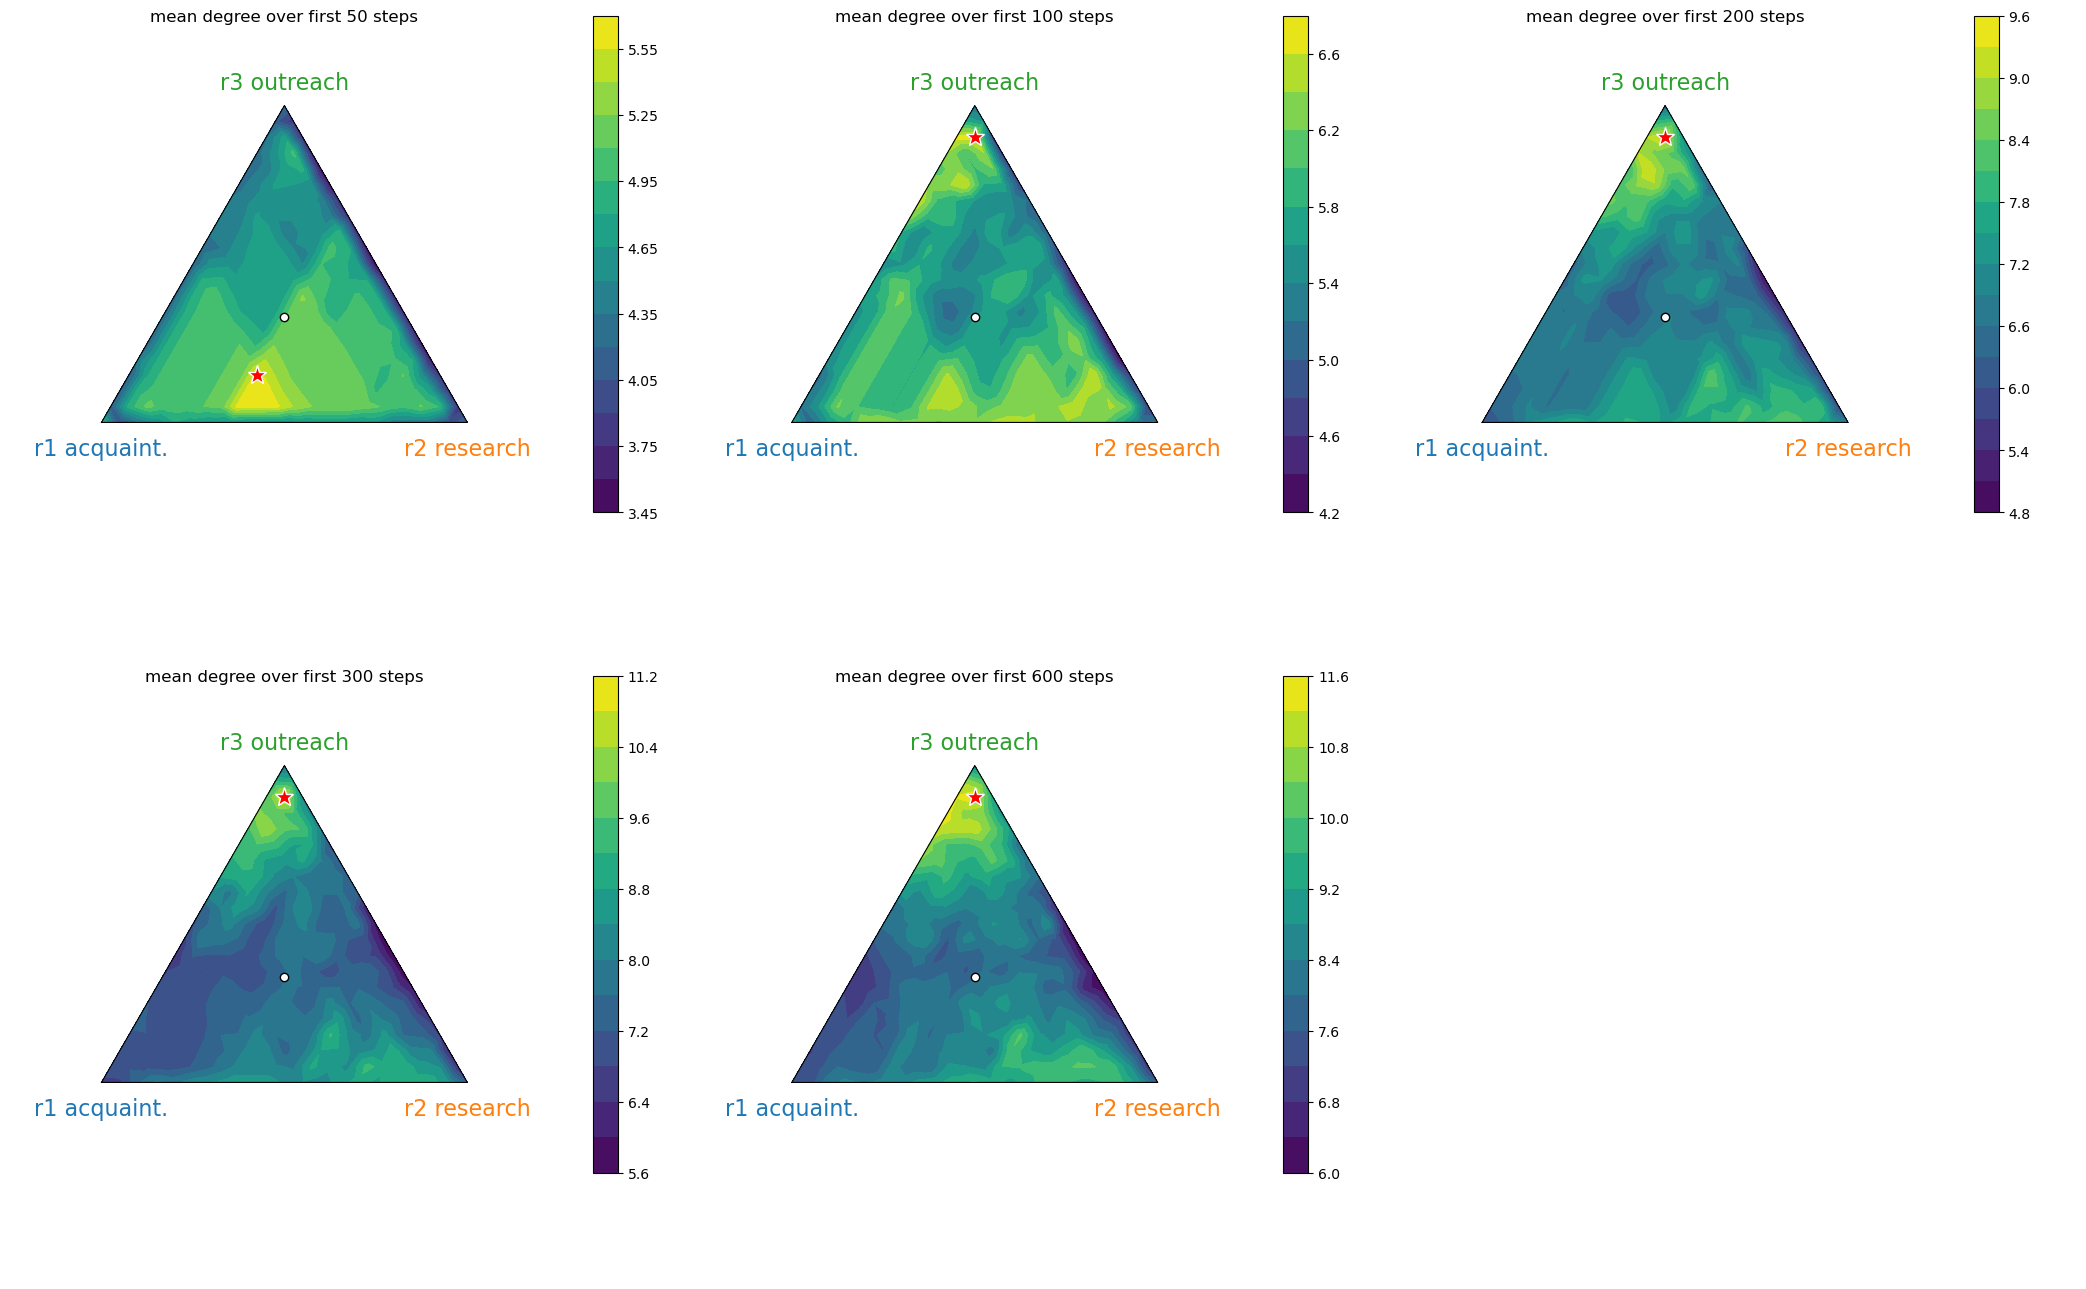

In [5]:
H = G['horizons']; hor = G['horizon'].mean(1)
fig, axs = plt.subplots(2, 3, figsize=(21, 14)); axs = axs.ravel(); axs[-1].axis('off')
for j, h in enumerate(H):
    best = tri_map(axs[j], grid, hor[:, j], f'mean degree over first {h} steps')
    print(f'H = {h:4d}: best allocation {best}')
plt.tight_layout(); plt.show()

## 4. 学習の診断

### 4.1 雑音と傾きの比較

学習者は評価窓 $\tau$ ごとの平均次数で「良くなったか」を判断します。一歩 $\eta$ 動いたときの次数の変化が、窓平均の雑音より小さければ、良し悪しはほぼ偶然で決まります。

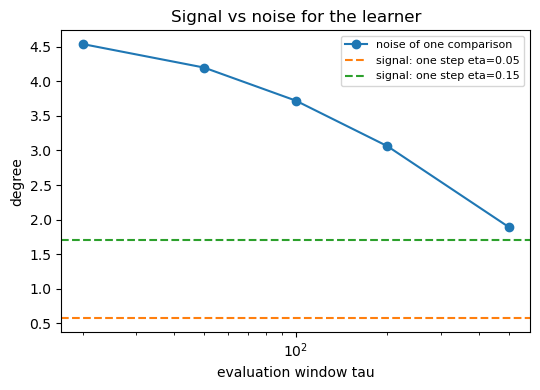

typical slope (degree per unit move): 11.41
tau=  20: comparison noise 4.54   S/N eta=0.05: 0.13   eta=0.15: 0.38
tau=  50: comparison noise 4.20   S/N eta=0.05: 0.14   eta=0.15: 0.41
tau= 100: comparison noise 3.72   S/N eta=0.05: 0.15   eta=0.15: 0.46
tau= 200: comparison noise 3.06   S/N eta=0.05: 0.19   eta=0.15: 0.56
tau= 500: comparison noise 1.89   S/N eta=0.05: 0.30   eta=0.15: 0.90


In [6]:
# 配分を固定した長いランで、評価窓ごとの雑音を測る (均等配分と最適配分、各12シード)
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor
from model2_tools import focal_run
TAUS = [20, 50, 100, 200, 500]; T_LONG, BURN = 3200, 200
jobs = [(np.array(x), 500 + s, dict(DEFAULT, T=T_LONG)) for x in ([1/3, 1/3, 1/3], opt_sim) for s in range(12)]
with ProcessPoolExecutor(mp_context=mp.get_context('fork')) as ex:
    longruns = list(ex.map(focal_run, jobs))
def wnoise(d, t):
    st = d[BURN:]; return st[: len(st) // t * t].reshape(-1, t).mean(1).std()
noise = np.array([[wnoise(r['deg'], t) for t in TAUS] for r in longruns]).mean(0)

# 一歩動いたときの次数の変化の典型値: 隣り合う格子点(単体上で 0.05)の差の中央値
d = np.abs(grid[:, None, :] - grid[None, :, :]).sum(2)
pairs = np.argwhere(np.isclose(d, 0.1))
slope = np.median(np.abs(steady[pairs[:, 0]] - steady[pairs[:, 1]])) / 0.05
# 学習者は「今の窓」と「過去の平均」を比べるので、比較の雑音はおよそ sqrt(2) 倍になる
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(TAUS, np.sqrt(2) * noise, 'o-', label='noise of one comparison')
for eta, col in ((0.05, 'C1'), (0.15, 'C2')):
    ax.axhline(slope * eta, ls='--', color=col, label=f'signal: one step eta={eta}')
ax.set_xscale('log'); ax.set_xlabel('evaluation window tau'); ax.set_ylabel('degree')
ax.legend(fontsize=8); ax.set_title('Signal vs noise for the learner'); plt.tight_layout(); plt.show()
print('typical slope (degree per unit move):', slope.round(2))
for t, n in zip(TAUS, noise):
    print(f'tau={t:4d}: comparison noise {np.sqrt(2)*n:.2f}   S/N eta=0.05: {slope*0.05/(np.sqrt(2)*n):.2f}   eta=0.15: {slope*0.15/(np.sqrt(2)*n):.2f}')

※ 傾きは12シード平均の隣接格子点の差から求めました。平均に残る雑音の分だけ少し過大なので、実際の信号雑音比は表示よりさらに小さくなります。

### 4.2 学習の軌跡

評価窓 $\tau$ と一歩の大きさ $\eta$ を変え、3つの初期値から6000ステップ学習させました。
星印は2節で求めたシミュレーション上の最適点です。

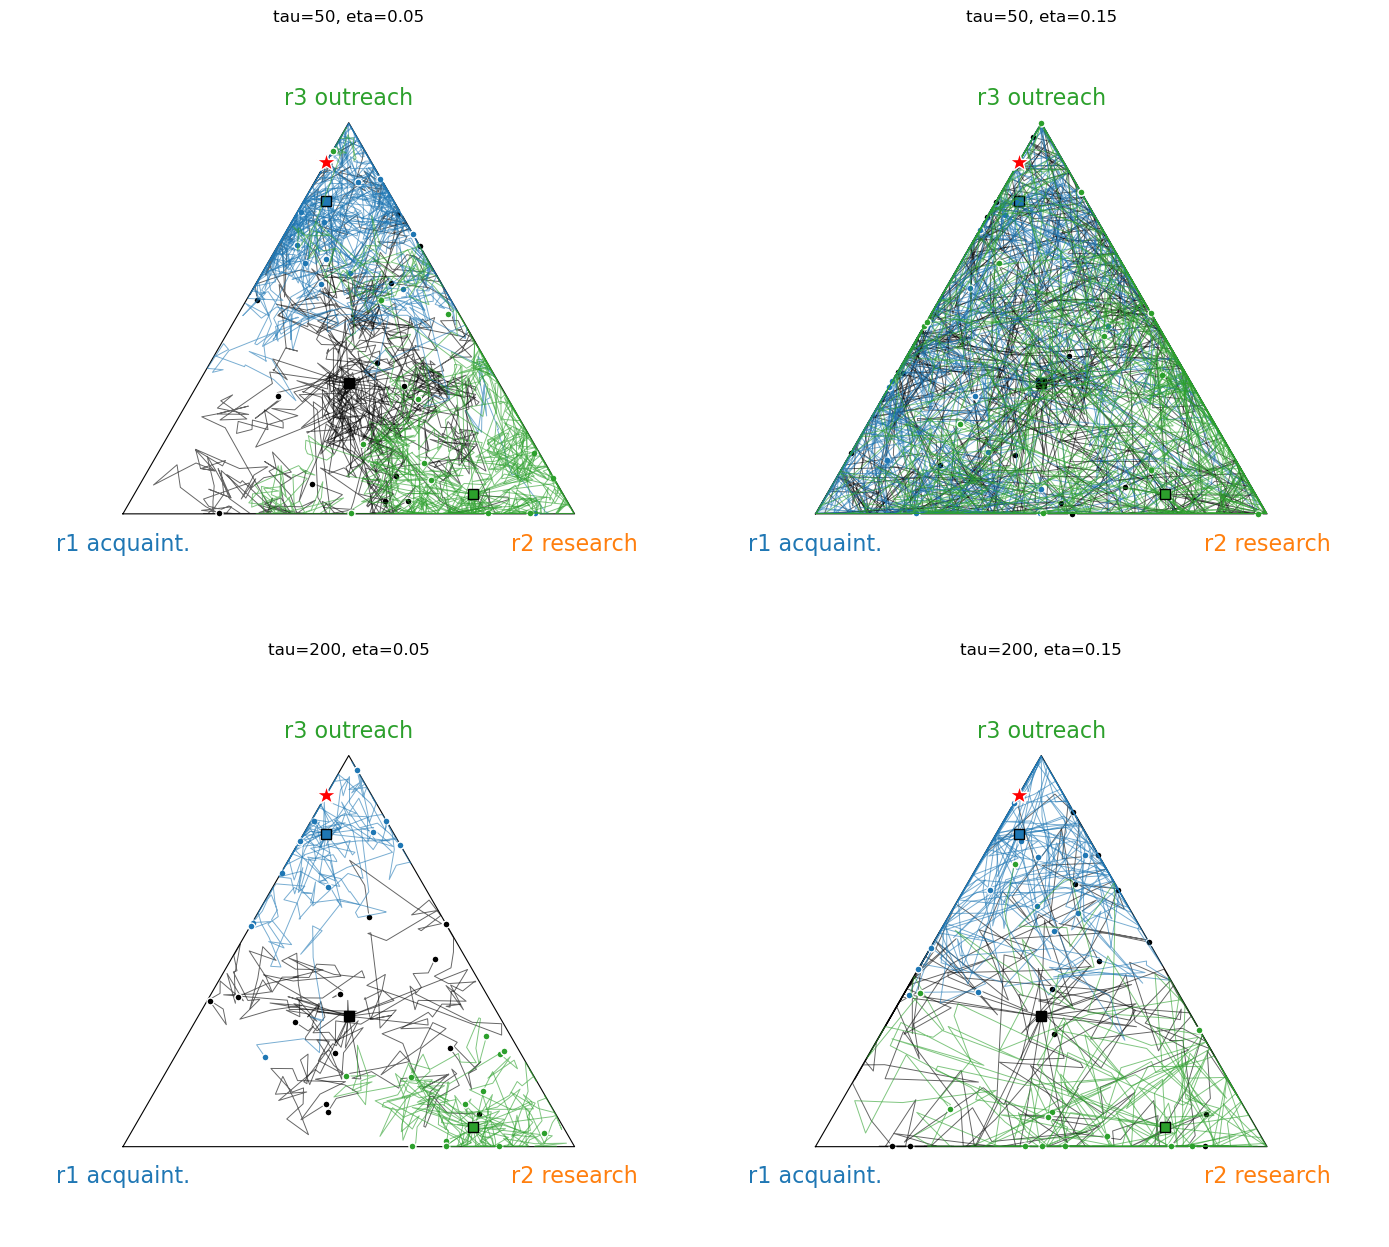

,tau,eta,start,final_x1,final_x2,final_x3,frac_x3_ge_06,L1_dist_to_opt,late_degree,regret
0,50,0.05,center,0.33,0.35,0.32,0.17,1.19,9.41,3.51
1,50,0.05,outreach,0.16,0.20,0.64,0.75,0.56,10.47,2.46
2,50,0.05,research,0.18,0.58,0.24,0.08,1.37,9.46,3.47
3,50,0.15,center,0.43,0.23,0.35,0.25,1.13,9.18,3.74
4,50,0.15,outreach,0.49,0.19,0.32,0.17,1.15,9.12,3.81
5,50,0.15,research,0.23,0.34,0.43,0.25,1.04,9.11,3.81
6,200,0.05,center,0.33,0.35,0.32,0.00,1.18,9.01,3.92
7,200,0.05,outreach,0.22,0.08,0.71,0.75,0.45,10.73,2.20
8,200,0.05,research,0.19,0.69,0.12,0.00,1.60,9.84,3.09
9,200,0.15,center,0.22,0.38,0.39,0.33,1.08,8.59,4.34


In [7]:
cols = {'center': 'k', 'outreach': 'tab:blue', 'research': 'tab:green'}
fig, axs = plt.subplots(2, 2, figsize=(14, 13)); axs = axs.ravel()
for ax, (tau, eta) in zip(axs, LEARN_CONFIGS):
    tri_axes(ax, f'tau={tau}, eta={eta}')
    for name, x0 in STARTS.items():
        for tr in L[f'{tau}_{eta}_{name}_traj']:
            u, w = tern(tr); ax.plot(u, w, '-', color=cols[name], lw=0.7, alpha=0.6)
            ax.plot(u[-1], w[-1], 'o', color=cols[name], ms=5, mec='w')
        ax.plot(*tern(x0), 's', color=cols[name], ms=7, mec='k')
    ax.plot(*tern(opt_sim), 'r*', ms=15, mec='w')
plt.tight_layout(); plt.show()
import pandas as pd
rows = []
for tau, eta in LEARN_CONFIGS:
    for name in STARTS:
        fx = L[f'{tau}_{eta}_{name}_traj'][:, -1]           # 各シードの終状態
        dg = L[f'{tau}_{eta}_{name}_deg'][:, -20:].mean(1)  # 最後の2000ステップの平均次数
        rows.append(dict(tau=tau, eta=eta, start=name,
                         final_x1=fx[:, 0].mean(), final_x2=fx[:, 1].mean(), final_x3=fx[:, 2].mean(),
                         frac_x3_ge_06=(fx[:, 2] >= 0.6).mean(),
                         L1_dist_to_opt=np.abs(fx - opt_sim).sum(1).mean(),
                         late_degree=dg.mean(), regret=steady.max() - dg.mean()))
learn_tab = pd.DataFrame(rows).round(2)
learn_tab

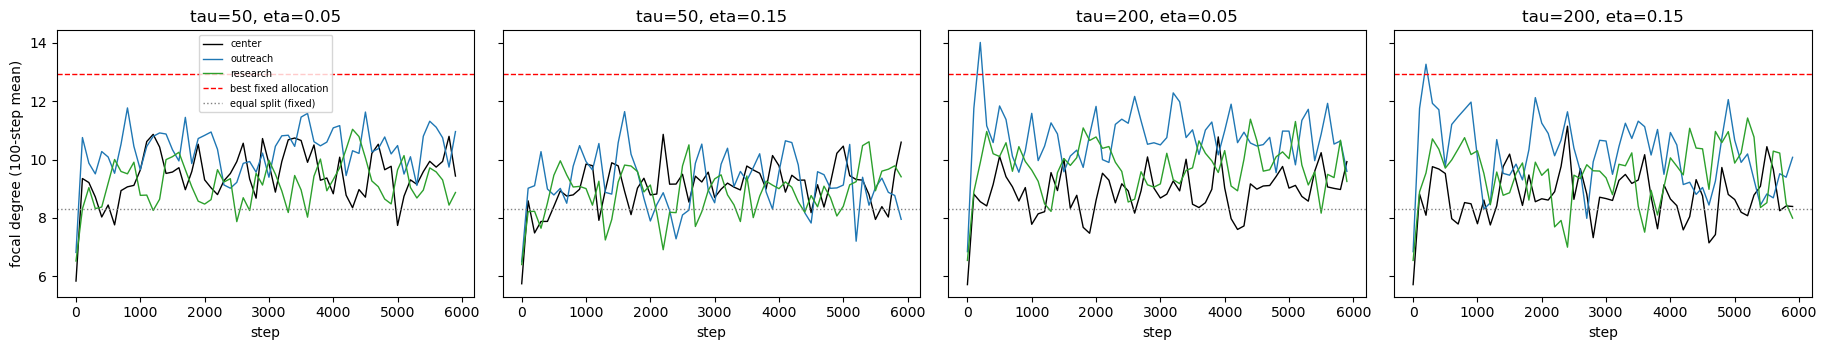

In [8]:
# 学習者の次数の推移と、最適配分に固定したときの次数との比較
fig, axs = plt.subplots(1, len(LEARN_CONFIGS), figsize=(4.6 * len(LEARN_CONFIGS), 3.6), sharey=True)
for ax, (tau, eta) in zip(axs, LEARN_CONFIGS):
    for name in STARTS:
        dg = L[f'{tau}_{eta}_{name}_deg'].mean(0)
        ax.plot(np.arange(len(dg)) * 100, dg, color=cols[name], label=name, lw=1)
    ax.axhline(steady.max(), color='r', ls='--', lw=1, label='best fixed allocation')
    ax.axhline(steady[ctr], color='gray', ls=':', lw=1, label='equal split (fixed)')
    ax.set_title(f'tau={tau}, eta={eta}'); ax.set_xlabel('step')
axs[0].set_ylabel('focal degree (100-step mean)'); axs[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [9]:
# 数値のまとめを保存
import json
summary = dict(
    mean_field_optimum=opt_mf.round(2).tolist(),
    simulation_optimum_degree=opt_sim.round(2).tolist(),
    simulation_optimum_pagerank=opt_pr.round(2).tolist(),
    best_degree=float(steady.max().round(2)), equal_split_degree=float(steady[ctr].round(2)),
    population_mean_degree=float(G['pop_deg'].mean().round(2)),
    best_by_horizon={int(h): grid[np.argmax(hor[:, j])].round(2).tolist() for j, h in enumerate(H)},
)
json.dump(summary, open(f'{R2}/summary.json', 'w'), indent=1)
learn_tab.to_csv(f'{R2}/learning_table.csv', index=False)
summary

{'mean_field_optimum': [0.14, 0.0, 0.86],
 'simulation_optimum_degree': [0.1, 0.0, 0.9],
 'simulation_optimum_pagerank': [0.35, 0.0, 0.65],
 'best_degree': 12.93,
 'equal_split_degree': 8.32,
 'population_mean_degree': 9.39,
 'best_by_horizon': {50: [0.5, 0.35, 0.15],
  100: [0.05, 0.05, 0.9],
  200: [0.05, 0.05, 0.9],
  300: [0.05, 0.05, 0.9],
  600: [0.05, 0.05, 0.9]}}

## まとめ(12シード)

- **最適配分**: 学習者の最適反応は、アウトリーチ9割、知り合い1割、研究0の配分でした。平均場近似の予測 (0.14, 0, 0.86) とほぼ一致します。次数は 12.9 で、均等配分の 8.3 より約5割多く、集団平均の 9.4 も大きく上回ります。
- **知り合いは少しだけ必要**: アウトリーチ10割にすると、次数は 9.8 まで落ちます。アウトリーチで得た遠いつながりを、知り合いの知り合いで広げる分が必要です。
- **指標による違い**: PageRank で測ると、最適点は知り合いを3〜4割に増やした (0.35, 0, 0.65) に動きます。有名な人に知られるには、知り合い戦略がより効くと読めます。
- **山は2つある**: アウトリーチをほぼ使わない研究寄りの配分 (0.3, 0.65, 0.05) にも、次数 11.3 の局所的な山があります。アウトリーチ割合が 0.3〜0.6 の範囲は谷で、次数は 9.3〜10 程度に下がります。均等配分はこの谷の中にあります。
- **時間スケール**: 開始から50ステップでの最適は、知り合いと研究中心の (0.5, 0.35, 0.15) でした。100ステップ以降は、アウトリーチ9割が最適になります。短期なら知り合いと研究、長期ならアウトリーチ、という切り替わりがあります。
- **死亡リスク**: 研究を0にして、知り合いと閾値未満のアウトリーチだけに振った配分で、死亡が多くなりました。
- **学習の失敗**: どの設定でも、学習者は最適点に収束しませんでした。比較1回の信号雑音比は、評価窓500・一歩0.15でも 0.9 で、それ以外はさらに小さい値でした。一歩ごとの良し悪しが、ほぼ偶然で決まります。
- **初期値への依存**: 学習の行き先は、初期値でほぼ決まりました。アウトリーチ寄りから始めると、5〜7割のシードがアウトリーチの山に残ります。均等配分から始めると、多くは谷の付近をさまよいます。学習者の後半の次数は 8.6〜10.7 で、最適な固定配分より 2〜4 低い値でした。
